# Phase 4 — Author-aligned Figure 3 experiment (C1 and C2)

**Read first:** This is a separate experimental branch, not a replacement for Phase 3. The first author's public `network_zoo.py` has stride-1 C1 convolutions (contrary to Appendix B.3's stride-2 notation), and convolutional dropout in C2. The notebook retrains **C1/C2 SB and LB** from scratch with those two architectural changes. F1 is **not retrained** because the inspected author repository does not provide an F1 reference architecture.

The notebook reads the repository's **single root `requirements.txt`**. It saves checkpoints every five epochs on Drive; restarting Colab can resume by copying those checkpoints back. Start with the **benchmark cells and share their outputs** before launching expensive training. All plots derive from measured JSONs, not fixed data points. Phase 3 results are never overwritten.

Author reference: https://github.com/keskarnitish/large-batch-training/blob/master/network_zoo.py

## 1. Clone or pull your private repo (GitHub token in Colab Secrets)

In [ ]:
import subprocess
import os
from pathlib import Path
from google.colab import userdata

REPO = Path("/content/advanced-ml-paper-reproductions")
TOKEN = userdata.get("GITHUB_TOKEN")

assert TOKEN, "Missing GITHUB_TOKEN in Colab Secrets"

env = os.environ.copy()
env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "http.extraheader"
import base64
auth = base64.b64encode(f"x-access-token:{TOKEN}".encode()).decode()
env["GIT_CONFIG_VALUE_0"] = f"AUTHORIZATION: basic {auth}"

if REPO.exists():
    # Discard Colab-only Git changes and match GitHub main.
    subprocess.run(
        ["git", "-C", str(REPO), "fetch", "origin", "main"],
        check=True, env=env
    )
    subprocess.run(
        ["git", "-C", str(REPO), "reset", "--hard", "FETCH_HEAD"],
        check=True
    )
else:
    subprocess.run(
        ["git", "clone", "https://github.com/vepaan/advanced-ml-paper-reproductions.git", str(REPO)],
        check=True, env=env
    )

print("Repository synchronized.")
subprocess.run(["git", "-C", str(REPO), "log", "-1", "--oneline"], check=True)

Repository synchronized.


CompletedProcess(args=['git', '-C', '/content/advanced-ml-paper-reproductions', 'log', '-1', '--oneline'], returncode=0)

## 2. Mount Drive and use the project-wide dependencies

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import sys, subprocess
from pathlib import Path
REPO = Path('/content/advanced-ml-paper-reproductions')
PROJECT = REPO / 'paper2-large-batch'
assert (REPO / 'requirements.txt').is_file()
assert (PROJECT / 'src/phase4_models.py').is_file(), 'First copy the Phase 4 source files into your private Git repo and push.'
subprocess.run([sys.executable,'-m','pip','install','-r',str(REPO/'requirements.txt')], check=True)
import torch
assert torch.cuda.is_available(), 'Select an A100 GPU runtime under Runtime → Change runtime type.'
print('CUDA:',torch.cuda.get_device_name(0),'torch:',torch.__version__)
DRIVE_ROOT = Path('/content/drive/MyDrive/ML-Paper-Reproductions/paper2/phase4_author_aligned')
LOCAL_ROOT = Path('/content/paper2_phase4_author_aligned')
DRIVE_ROOT.mkdir(parents=True,exist_ok=True)
LOCAL_ROOT.mkdir(parents=True,exist_ok=True)
os.chdir(PROJECT)
print('Working directory:',Path.cwd())

Mounted at /content/drive
CUDA: Tesla T4 torch: 2.14.1+cu130
Working directory: /content/advanced-ml-paper-reproductions/paper2-large-batch


## 3. Validate CIFAR-10 and inspect the new architecture

In [ ]:
import sys, subprocess
from pathlib import Path
cifar = REPO / 'paper1-generalization/data/cifar-10-batches-py'
if not (cifar / 'data_batch_1').is_file():
    from torchvision.datasets import CIFAR10
    print('Downloading CIFAR-10 into the Paper 1 shared data directory...')
    CIFAR10(root=str(cifar.parent),train=True,download=True)
    CIFAR10(root=str(cifar.parent),train=False,download=True)
assert (cifar / 'data_batch_1').is_file()
for file in ['phase4_models.py','phase4_train.py','phase4_interpolate.py']:
    subprocess.run([sys.executable,'-m','py_compile','src/'+file],check=True)
subprocess.run([sys.executable,'-u','src/phase4_models.py'],check=True)
subprocess.run([sys.executable,'-u','src/data.py','--panel','C1'],check=True)
print('Validation complete. Send this cell output if any parameter counts/shapes are surprising.')

Validation complete. Send this cell output if any parameter counts/shapes are surprising.


## 4. Benchmark all four training configurations — **STOP AND SEND THIS OUTPUT**

In [ ]:
import subprocess,sys
for panel in ('C1','C2'):
    for regime in ('SB','LB'):
        print(f'\n===== BENCHMARK {panel} {regime} =====',flush=True)
        subprocess.run([sys.executable,'-u','src/phase4_train.py',
                        '--panel',panel,'--regime',regime,'--mode','benchmark',
                        '--device','cuda','--bench-steps','8'],check=True)
print('BENCHMARKS COMPLETE. Share these results before launching training.')


===== BENCHMARK C1 SB =====

===== BENCHMARK C1 LB =====

===== BENCHMARK C2 SB =====

===== BENCHMARK C2 LB =====
BENCHMARKS COMPLETE. Share these results before launching training.


In [ ]:
import subprocess
import sys

subprocess.run([
    sys.executable, "-u", "src/phase4_train.py",
    "--panel", "C2",
    "--regime", "LB",
    "--mode", "benchmark",
    "--device", "cuda",
    "--precision", "fp16",
    "--bench-steps", "3"
], check=True)

CompletedProcess(args=['/usr/bin/python3', '-u', 'src/phase4_train.py', '--panel', 'C2', '--regime', 'LB', '--mode', 'benchmark', '--device', 'cuda', '--precision', 'fp16', '--bench-steps', '3'], returncode=0)

## 5. Training cells — run **one at a time** after benchmarks

Each cell trains to **50 total epochs** (not 50 more after resume) using Adam 0.001 and the exact paper batch sizes (256 SB / 5000 LB). We use a fixed initial budget rather than stopping early based on a 2,048-image probe. If the training set is not adequately fit, **do not blindly extend**: inspect metrics and decide a recorded Phase 4 continuation (e.g. 0.0002 LR) first. Each checkpoint (`last.pt`) is backed up every 5 epochs. The final `endpoint.pt` and `metrics.json` also go to Drive.

If Colab restarts, re-run setup/validation and the restore cell below. It copies only Phase 4 checkpoints, never Phase 3.

In [ ]:
import shutil
for panel in ('C1','C2'):
    for regime in ('SB','LB'):
        name=f'{panel}_{regime}_seed42'
        local=LOCAL_ROOT/name
        remote=DRIVE_ROOT/name
        if remote.is_dir() and (remote/'last.pt').is_file() and not (local/'last.pt').is_file():
            shutil.copytree(remote, local, dirs_exist_ok=True)
            print('Restored',name)
print('Restore step complete.')

Restore step complete.


### Train C1 SB — separate resumable experiment

In [ ]:
!python -u src/phase4_train.py \
  --mode train --panel C1 --regime SB \
  --device cuda --precision fp16 --seed 42 \
  --max-epochs 50 --checkpoint-every 5 \
  --output-root {LOCAL_ROOT} --backup-root {DRIVE_ROOT}

CONFIG {'panel': 'C1', 'regime': 'SB', 'seed': 42, 'batch': 256, 'initial_lr': 0.001, 'architecture_version': 'phase4-author-keras-architecture-v1', 'data': 'raw/255; no augmentation', 'optimizer': 'Adam', 'precision': 'fp16'} device cuda parameters 1757130
GPU Tesla T4 total_GiB 14.56
RESUMED at epoch 20
C1_SB epoch=21 train_step_CE=0.19899
C1_SB epoch=22 train_step_CE=0.19200
C1_SB epoch=23 train_step_CE=0.17351
C1_SB epoch=24 train_step_CE=0.16306
C1_SB epoch=25 train_step_CE=0.15273 probe_train_acc=92.29% probe_test_acc=74.02%
Drive sync: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/phase4_author_aligned/C1_SB_seed42
C1_SB epoch=26 train_step_CE=0.15037
C1_SB epoch=27 train_step_CE=0.14289
C1_SB epoch=28 train_step_CE=0.13172
C1_SB epoch=29 train_step_CE=0.13220
C1_SB epoch=30 train_step_CE=0.12606 probe_train_acc=93.41% probe_test_acc=74.56%
Drive sync: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/phase4_author_aligned/C1_SB_seed42
C1_SB epoch=31 train_step_CE=0.12

### Train C1 LB — separate resumable experiment

In [ ]:
!python -u src/phase4_train.py \
  --mode train --panel C1 --regime LB \
  --device cuda --precision fp16 --seed 42 \
  --max-epochs 50 --checkpoint-every 5 \
  --output-root {LOCAL_ROOT} --backup-root {DRIVE_ROOT}

CONFIG {'panel': 'C1', 'regime': 'LB', 'seed': 42, 'batch': 5000, 'initial_lr': 0.001, 'architecture_version': 'phase4-author-keras-architecture-v1', 'data': 'raw/255; no augmentation', 'optimizer': 'Adam', 'precision': 'fp16'} device cuda parameters 1757130
GPU Tesla T4 total_GiB 14.56
C1_LB epoch=1 train_step_CE=1.87047
C1_LB epoch=2 train_step_CE=1.45062
C1_LB epoch=3 train_step_CE=1.25438
C1_LB epoch=4 train_step_CE=1.11602
C1_LB epoch=5 train_step_CE=1.01228 probe_train_acc=51.03% probe_test_acc=51.27%
Drive sync: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/phase4_author_aligned/C1_LB_seed42
C1_LB epoch=6 train_step_CE=0.93293
C1_LB epoch=7 train_step_CE=0.87431
C1_LB epoch=8 train_step_CE=0.82190
C1_LB epoch=9 train_step_CE=0.77642
C1_LB epoch=10 train_step_CE=0.74434 probe_train_acc=69.04% probe_test_acc=65.72%
Drive sync: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/phase4_author_aligned/C1_LB_seed42
C1_LB epoch=11 train_step_CE=0.69398
C1_LB epoch=12 train_ste

### Train C2 SB — separate resumable experiment

In [ ]:
!python -u src/phase4_train.py \
  --mode train --panel C2 --regime SB \
  --device cuda --precision fp16 --seed 42 \
  --max-epochs 50 --checkpoint-every 5 \
  --output-root {LOCAL_ROOT} --backup-root {DRIVE_ROOT}

CONFIG {'panel': 'C2', 'regime': 'SB', 'seed': 42, 'batch': 256, 'initial_lr': 0.001, 'architecture_version': 'phase4-author-keras-architecture-v1', 'data': 'raw/255; no augmentation', 'optimizer': 'Adam', 'precision': 'fp16'} device cuda parameters 14987210
GPU Tesla T4 total_GiB 14.56
C2_SB epoch=1 train_step_CE=1.92966
C2_SB epoch=2 train_step_CE=1.53669
C2_SB epoch=3 train_step_CE=1.22092
C2_SB epoch=4 train_step_CE=0.97457
C2_SB epoch=5 train_step_CE=0.83515 probe_train_acc=62.84% probe_test_acc=61.82%
Drive sync: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/phase4_author_aligned/C2_SB_seed42
C2_SB epoch=6 train_step_CE=0.73767
C2_SB epoch=7 train_step_CE=0.66624
C2_SB epoch=8 train_step_CE=0.60671
C2_SB epoch=9 train_step_CE=0.56980
C2_SB epoch=10 train_step_CE=0.51768 probe_train_acc=85.84% probe_test_acc=81.40%
Drive sync: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/phase4_author_aligned/C2_SB_seed42
C2_SB epoch=11 train_step_CE=0.47702
C2_SB epoch=12 train_ste

### Train C2 LB — separate resumable experiment

In [ ]:
!python -u src/phase4_train.py \
  --mode train --panel C2 --regime LB \
  --device cuda --precision fp16 --seed 42 \
  --max-epochs 50 --checkpoint-every 5 \
  --output-root {LOCAL_ROOT} --backup-root {DRIVE_ROOT}

CONFIG {'panel': 'C2', 'regime': 'LB', 'seed': 42, 'batch': 5000, 'initial_lr': 0.001, 'architecture_version': 'phase4-author-keras-architecture-v1', 'data': 'raw/255; no augmentation', 'optimizer': 'Adam', 'precision': 'fp16'} device cuda parameters 14987210
GPU Tesla T4 total_GiB 14.56
[W1021 01:24:20.457915358 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 5909774336 bytes (free: 2505900032, total: 15637086208).
[W1021 01:24:21.214826393 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 5909774336 bytes (free: 4192010240, total: 15637086208).
[W1021 01:24:22.341894625 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 5909774336 bytes (free: 4850515968, total: 15637086208).
[W1021 01:24:22.362876977 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 5909774336 bytes (free: 4850

## 6. Inspect all endpoint metrics BEFORE interpolation

In [ ]:
import json
from pathlib import Path
for panel in ('C1','C2'):
    for regime in ('SB','LB'):
        name=f'{panel}_{regime}_seed42'
        f=LOCAL_ROOT/name/'metrics.json'
        assert f.is_file(),f'Missing {f}. Complete that run first.'
        x=json.loads(f.read_text())
        print(f"{name}: epochs={x['epoch']}  trainCE={x['train']['loss']:.5f} "
              f"trainAcc={100*x['train']['accuracy']:.3f}%  "
              f"testAcc={100*x['test']['accuracy']:.3f}%")
print('Send this output before deciding whether to continue training or interpolate.')

C1_SB_seed42: epochs=50  trainCE=0.01414 trainAcc=99.622%  testAcc=79.070%
C1_LB_seed42: epochs=50  trainCE=0.09838 trainAcc=96.554%  testAcc=74.040%
C2_SB_seed42: epochs=50  trainCE=0.04697 trainAcc=98.438%  testAcc=86.590%
C2_LB_seed42: epochs=50  trainCE=0.40126 trainAcc=87.056%  testAcc=78.300%
Send this output before deciding whether to continue training or interpolate.


## 7. Interpolate each new pair (61 points, BN recalibration)

Run these only when we accept the trained endpoints. The Phase 4 wrapper calls the same interpolation method used in Phase 3, but constructs the author-aligned models. It evaluates all 50k train and 10k test images at each α, with BatchNorm statistics recalibrated on the first 4,096 train images. Each result is saved to Drive immediately.

### C1 61-point interpolation

In [ ]:
import subprocess,sys,shutil,json
panel='C1'
for regime in ('SB','LB'):
    assert (LOCAL_ROOT/f'{panel}_{regime}_seed42'/'endpoint.pt').is_file()
subprocess.run([sys.executable,'-u','src/phase4_interpolate.py',
                '--panel',panel,'--device','cuda','--output-root',str(LOCAL_ROOT),
                '--points','61','--bn-policy','recalibrate','--bn-examples','4096',
                '--eval-batch','512'],check=True)
source=LOCAL_ROOT/f'{panel}_interpolation.json'
result=json.loads(source.read_text())
assert len(result['points'])==61
shutil.copy2(source,DRIVE_ROOT/source.name)
print('Saved Phase 4',panel,'interpolation to Drive')

Saved Phase 4 C1 interpolation to Drive


### C2 61-point interpolation

In [ ]:
import subprocess,sys,shutil,json
panel='C2'
for regime in ('SB','LB'):
    assert (LOCAL_ROOT/f'{panel}_{regime}_seed42'/'endpoint.pt').is_file()
subprocess.run([sys.executable,'-u','src/phase4_interpolate.py',
                '--panel',panel,'--device','cuda','--output-root',str(LOCAL_ROOT),
                '--points','61','--bn-policy','recalibrate','--bn-examples','4096',
                '--eval-batch','512'],check=True)
source=LOCAL_ROOT/f'{panel}_interpolation.json'
result=json.loads(source.read_text())
assert len(result['points'])==61
shutil.copy2(source,DRIVE_ROOT/source.name)
print('Saved Phase 4',panel,'interpolation to Drive')

Saved Phase 4 C2 interpolation to Drive


## 8. Compare final Phase 3 and Phase 4 curves (inline and PNG/PDF)

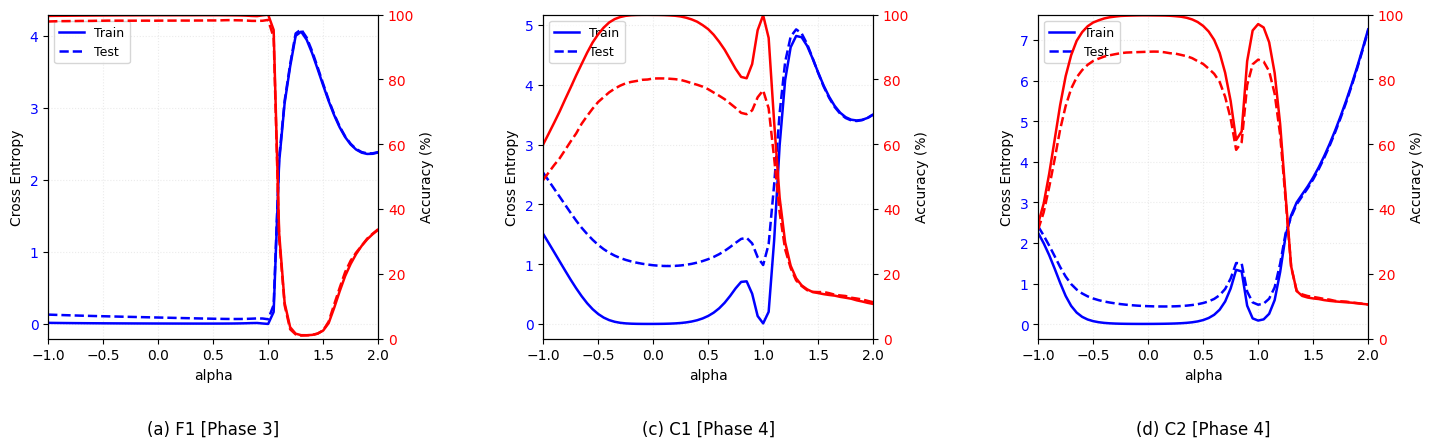

Saved final figure: /content/paper2_phase4_author_aligned/figures


In [ ]:
import json, numpy as np, matplotlib.pyplot as plt, shutil
from pathlib import Path
PHASE3 = PROJECT / 'results' / 'paper2' / 'final_61'
figure_dir=LOCAL_ROOT/'figures'
figure_dir.mkdir(exist_ok=True)
label=dict(F1='a',C1='c',C2='d')
fig,axes=plt.subplots(1,3,figsize=(15,4.5))
for ax,panel in zip(axes,['F1','C1','C2']):
    source=(PHASE3 if panel=='F1' else LOCAL_ROOT)/f'{panel}_interpolation.json'
    assert source.is_file(),f'Not found: {source}'
    d=json.loads(source.read_text()); pts=sorted(d['points'],key=lambda x:x['alpha'])
    a=np.array([x['alpha'] for x in pts]);
    assert len(pts)==61 and np.any(np.isclose(a,0)) and np.any(np.isclose(a,1))
    losses=[np.array([x[k] for x in pts]) for k in ('train_loss','test_loss')]
    accs=[100*np.array([x[k] for x in pts]) for k in ('train_accuracy','test_accuracy')]
    ax.plot(a,losses[0],'b-',lw=1.8,label='Train')
    ax.plot(a,losses[1],'b--',lw=1.8,label='Test')
    ax.set(xlim=(-1,2),xlabel='alpha',ylabel='Cross Entropy')
    ax.tick_params(axis='y',labelcolor='blue')
    ax.grid(alpha=.25,ls=':')
    other=ax.twinx()
    other.plot(a,accs[0],'r-',lw=1.8)
    other.plot(a,accs[1],'r--',lw=1.8)
    other.set(ylim=(0,100),ylabel='Accuracy (%)')
    other.tick_params(axis='y',labelcolor='red')
    ax.set_title(f'({label[panel]}) {panel}' + (' [Phase 3]' if panel=='F1' else ' [Phase 4]'),y=-.32)
    ax.legend(loc='upper left',fontsize=9)
fig.subplots_adjust(left=.06,right=.94,bottom=.23,top=.95,wspace=.50)
for ext in ('png','pdf'):
    dst=figure_dir/f'figure3_phase4_author_aligned.{ext}'
    fig.savefig(dst,dpi=300,bbox_inches='tight')
    shutil.copy2(dst,DRIVE_ROOT/dst.name)
plt.show();plt.close(fig)
print('Saved final figure:',figure_dir)

## 9. Quantitative endpoint comparison: original versus Phase 4

In [ ]:
for panel in ('C1','C2'):
    old=json.loads((PHASE3/f'{panel}_interpolation.json').read_text())
    new=json.loads((LOCAL_ROOT/f'{panel}_interpolation.json').read_text())
    print(f'\n{panel}:')
    for regime,target in [('SB',0.),('LB',1.)]:
        x=next(p for p in old['points'] if abs(p['alpha']-target)<1e-8)
        y=next(p for p in new['points'] if abs(p['alpha']-target)<1e-8)
        print(f'  {regime}: Phase3 train/test = {x["train_accuracy"]:.3%}/{x["test_accuracy"]:.3%}; '
              f'Phase4 = {y["train_accuracy"]:.3%}/{y["test_accuracy"]:.3%}; '
              f'Phase4 test CE={y["test_loss"]:.5f}')


C1:
  SB: Phase3 train/test = 99.988%/70.790%; Phase4 = 99.926%/80.290%; Phase4 test CE=0.98391
  LB: Phase3 train/test = 99.794%/66.440%; Phase4 = 99.820%/76.640%; Phase4 test CE=0.98732

C2:
  SB: Phase3 train/test = 99.718%/86.500%; Phase4 = 99.796%/88.560%; Phase4 test CE=0.44604
  LB: Phase3 train/test = 99.610%/81.100%; Phase4 = 97.094%/86.120%; Phase4 test CE=0.48192
